In [114]:
# Imports, etc 

import numpy as np
import pandas as pd
import seaborn as sns
PREVIOUS_MAX_ROWS = pd.options.display.max_rows
pd.options.display.max_rows = 20
np.random.seed(12345)
import matplotlib.pyplot as plt
import matplotlib
plt.rc('figure', figsize=(10, 6))
np.set_printoptions(precision=4, suppress=True)

# Project 2: Sleep Study (Python Edition)
### Author: Conrad Fritz and Emily Tsang
Date: 4/29/25

## Overview of Our Data and Project
In the modern day of technology and workaholics, it's incredibly difficult to consistently get good sleep. That being said, this project aims to analyze the sleep quality of adults while finding factors that may correlate with sleep quality to provide the best advice to getting a good night's rest. That being said, we're importing a data set I found on Kaggle. 

This data was imported from Kaggle's "Sleep Health and Lifestyle" data set published by Laksika Tharmalingam 2 years ago. See the following link to access it yourself! <https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset?resource=download>. 


In [115]:
sleepdata = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")
print(len(sleepdata))

374



### Summary of Sleep Data 
There are 13 separate columns that we can access and use for this project: 
- Person ID
- Gender
- Age
- Occupation
- Sleep Duration
- Quality of Sleep
- Physical Activity Level
- Stress Level
- BMI Category
- Blood Pressure
- Heart Rate
- Daily Steps
- Sleep Disorder

## Pre-processing the Data
When it comes to providing the best advice to getting consistently good sleep, there are some factors that we must consider. What are some aspects of a human that could help us get good sleep ? What are some aspects that may throw this data off track? With that in mind, I'd like to turn the attention to the "Sleep Disorder" field. This column is something that may throw off the data as the average quality of sleep for those with a disorder may be affected. Proof of this is shown with this summary of the average sleep quality by Sleep Disorder: 

In [116]:
sleep_summary = sleepdata["Quality of Sleep"].mean()

print(sleep_summary)

7.31283422459893



As we can see, the sleep quality of those with a sleep disorder are, on average, worse than those without a sleep disorder which seems to due to their sleep disorder. Thus, we'll be taking out the data with a sleep disorder out of our project. When we clean up the data like so: 

In [117]:
# Data Wrangling / Cleaning portion show below

cleaned = sleepdata[sleepdata['Sleep Disorder'].isna()]

columnfilter = cleaned.columns.drop('Sleep Disorder')
cleaned = cleaned.dropna(subset=columnfilter)


# Results
print(cleaned)
print("Cleaned rows (no sleep disorder):", len(cleaned))


# Mean of Quality of Sleep for people with no sleep disorder
sleep_summary = cleaned['Quality of Sleep'].mean()
print("Average Quality of Sleep (no disorder):", sleep_summary)

     Person ID  Gender  Age         Occupation  Sleep Duration  \
0            1    Male   27  Software Engineer             6.1   
1            2    Male   28             Doctor             6.2   
2            3    Male   28             Doctor             6.2   
7            8    Male   29             Doctor             7.8   
8            9    Male   29             Doctor             7.8   
..         ...     ...  ...                ...             ...   
341        342  Female   56             Doctor             8.2   
342        343  Female   56             Doctor             8.2   
343        344  Female   57              Nurse             8.1   
358        359  Female   59              Nurse             8.0   
359        360  Female   59              Nurse             8.1   

     Quality of Sleep  Physical Activity Level  Stress Level   BMI Category  \
0                   6                       42             6     Overweight   
1                   6                       60   


We should see an increase in the average quality of sleep. 


## Data Exploration: 
Now that we filtered our data, how do we get good sleep? What are some qualities that lead to higher duration and quality of sleep? As someone who's chased beauty rest for ages, I have a theory that those who are more physically active tend to have better sleep, as their ability to sleep is better through exhaustion. To test that out, we can graph the correlation between the duration of sleep and physical activity, and the quality of sleep and physical activity: 

### Duration vs Physical Activity Level 

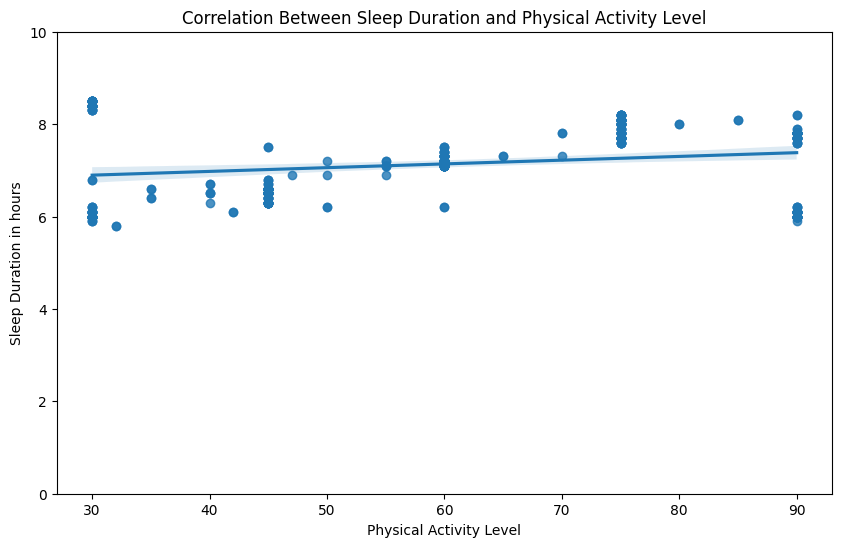

In [118]:
# Makes the plot 
sns.regplot(x = sleepdata["Physical Activity Level"], y = sleepdata["Sleep Duration"] , data = sleepdata, ci = 95)

# sets the title and labels
plt.title("Correlation Between Sleep Duration and Physical Activity Level")
plt.xlabel("Physical Activity Level")
plt.ylabel("Sleep Duration in hours")

plt.ylim(0, 10)    
# shows the plot 
plt.show()

#close this
plt.close('all')

### Quality vs Physical Activity Level 

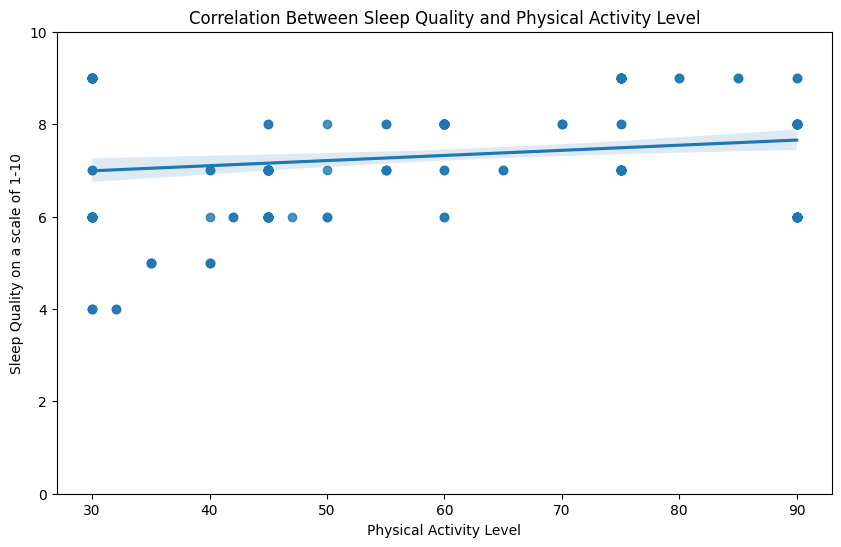

In [119]:
# Makes the plot 
sns.regplot(x = sleepdata["Physical Activity Level"], y = sleepdata["Quality of Sleep"] , data = sleepdata, ci = 95)

# sets the title and labels
plt.title("Correlation Between Sleep Quality and Physical Activity Level")
plt.xlabel("Physical Activity Level")
plt.ylabel("Sleep Quality on a scale of 1-10")

plt.ylim(0, 10)   
# shows the plot 
plt.show()

#close this
plt.close('all')

From these two graphs, we can see the Physical Activity Level of a person has fair correlation between sleep quality and sleep duration. In other words, the more physically active you are, the better chance of sleep quality you'll get. However, this wasn't a strong enough correlation to provide a solid argument for physical activity, so let's consider some other factors, like Stress: 

### Duration vs Stress

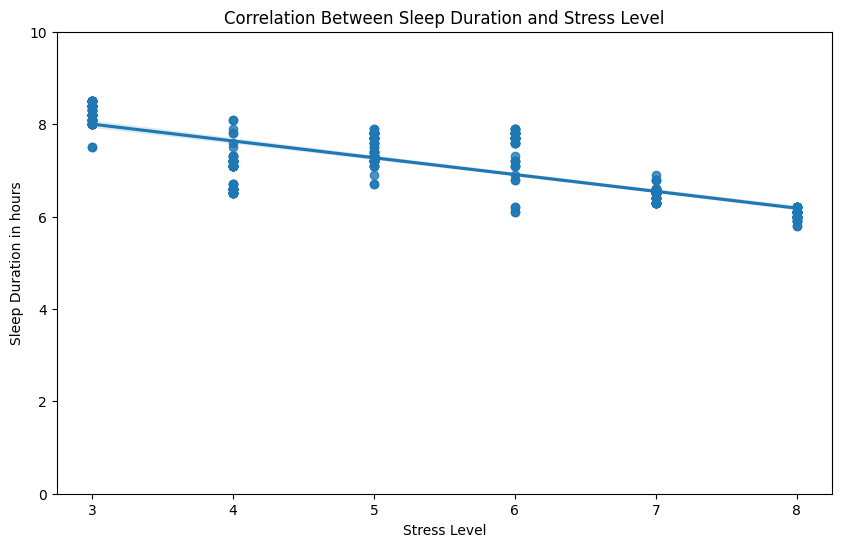

In [120]:
# Makes the plot 
sns.regplot(x = sleepdata["Stress Level"], y = sleepdata["Sleep Duration"] , data=sleepdata, ci=95)

# sets the title and labels
plt.title("Correlation Between Sleep Duration and Stress Level")
plt.xlabel("Stress Level")
plt.ylabel("Sleep Duration in hours")

plt.ylim(0, 10)   
# shows the plot 
plt.show()

#close this
plt.close('all')

### Quality of Sleep vs Stress

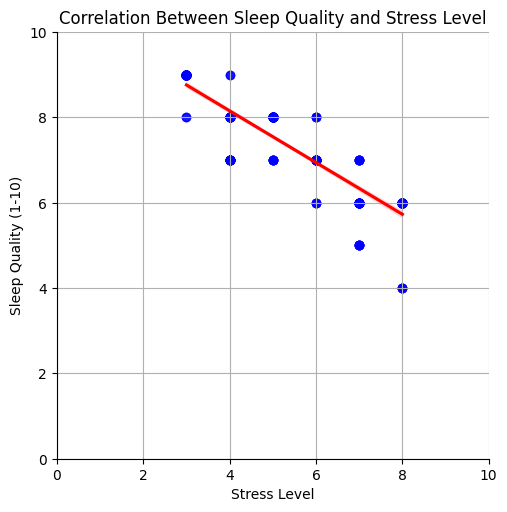

In [121]:
# Plot with seaborn, here I'm adding color to distinguish the line and scatter points
sns.lmplot(x = "Stress Level", y = "Quality of Sleep", data = sleepdata, scatter_kws = {'alpha':0.7, 'color':'blue'}, line_kws = {'color':'red'})

# Customize the plot
plt.title("Correlation Between Sleep Quality and Stress Level")
plt.xlabel("Stress Level")
plt.ylabel("Sleep Quality (1-10)")
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.grid(True)

# Show plot below
plt.show()

plt.close('all')


It's interesting to see the large difference in correlation between Stress and Physical Activity Level when pitted up against Quality and Duration of sleep. Clearly, from these graphs, stress levels have a negative linear relationship with the Quality of Sleep and Duration. With that being said, we have a more feasible advice to give to adults. Let's finally consider some other factors, like people's occupation and BMI category: 

### Quality of Sleep by BMI 

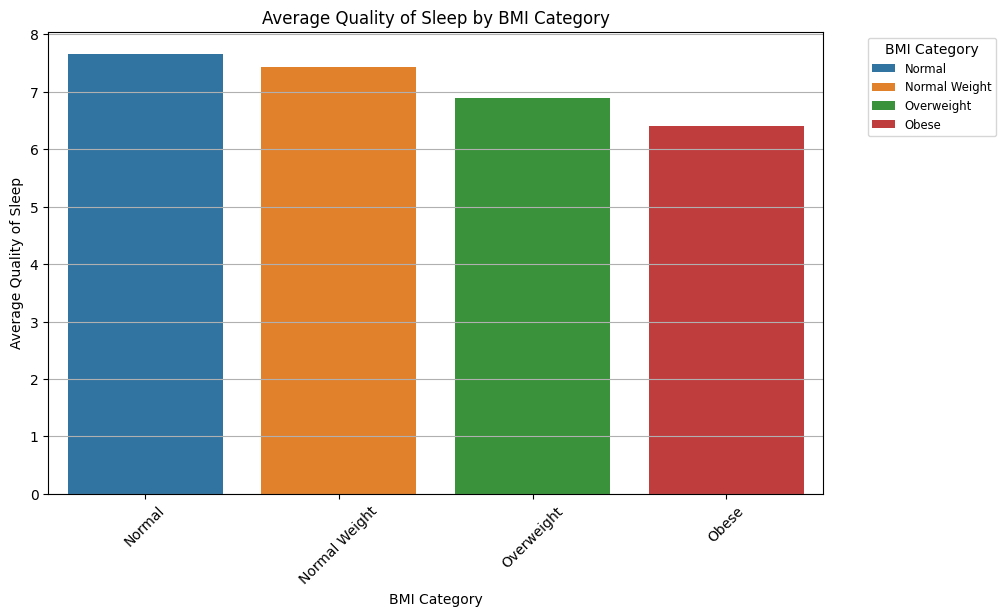

In [122]:
# Here, I only want BMI Category and Quality of Sleep, so I made a separate variable
bmi_quality = sleepdata.groupby("BMI Category")["Quality of Sleep"].mean().sort_values(ascending = False).reset_index()

# Plotting using my defined variable
sns.barplot(data = bmi_quality, x = "BMI Category", y = "Quality of Sleep", hue = "BMI Category", legend = True)

# Customize the plot
plt.title("Average Quality of Sleep by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Average Quality of Sleep")
plt.xticks(rotation = 45)
plt.grid(axis = "y")
plt.legend(title = "BMI Category", bbox_to_anchor = (1.05, 1), loc = 'upper left', fontsize = 'small')

# Show plot below
plt.show()

plt.close('all')


With this Bar Plot, we can see that people who are Overweight on the BMI scale clearly have a lower quality of sleep on average. However, it’s not by much, so I still wanted to consider occupation as a factor in the quality of sleep.

### Average Quality of Sleep by Occupation

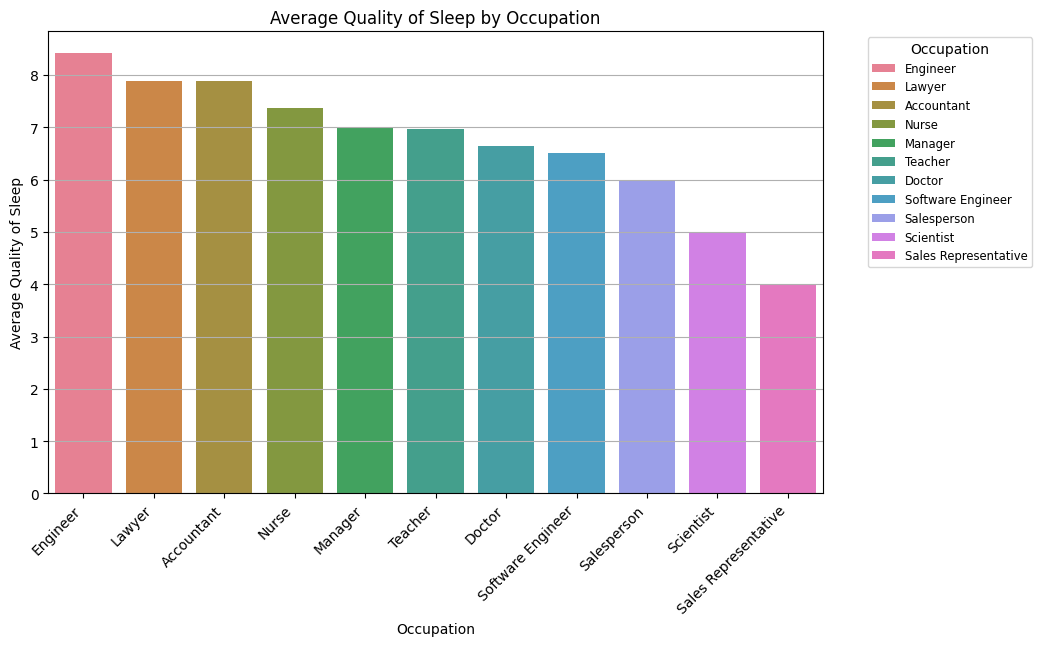

In [123]:
# We only want occupation and quality of sleep in this plot for comaprison
occupation_quality = sleepdata.groupby("Occupation")["Quality of Sleep"].mean().sort_values(ascending = False).reset_index()

# Plotting using my defined variable
sns.barplot(data = occupation_quality, x = "Occupation", y = "Quality of Sleep", hue = "Occupation", legend = True)

# Customize the plot
plt.title("Average Quality of Sleep by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Average Quality of Sleep")
plt.xticks(rotation = 45, ha = "right")
plt.grid(axis = "y")
plt.legend(title = "Occupation", bbox_to_anchor = (1.05, 1), loc = 'upper left', fontsize = 'small')

# Show plot below
plt.show()

plt.close('all')

It was interesting to see that there was a clear difference in sleep level between occupations where Salespeople had a lower quality of sleep on average while Engineers had a much higher quality of sleep on average. I thought that this may be related to stress, so I naturally plotted the correlation between stress and occupation:

### Average Stress Level by Occupation

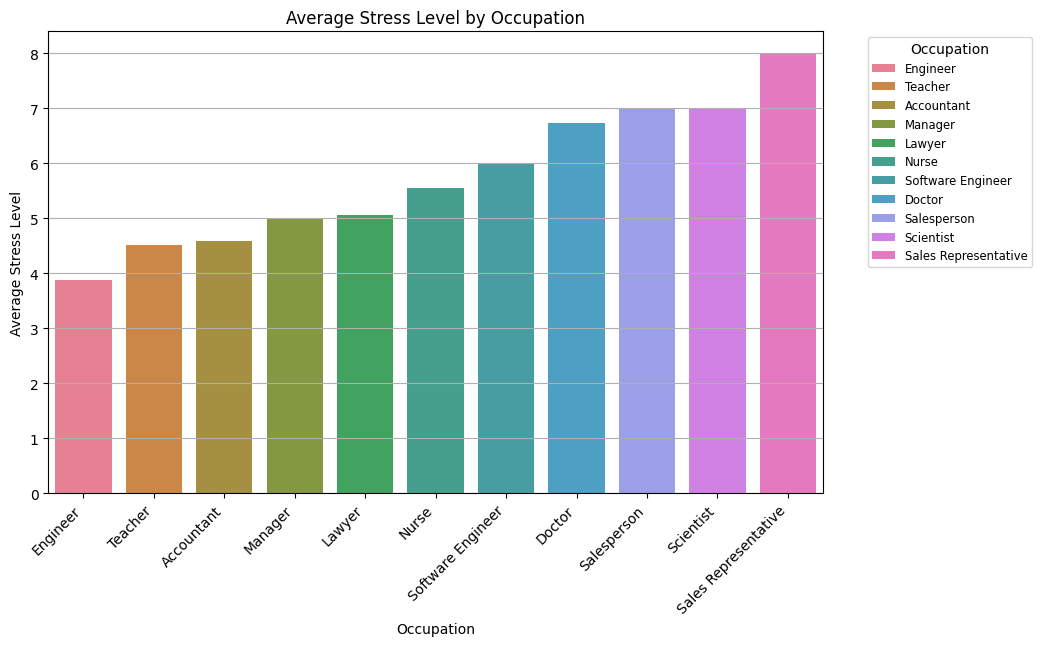

In [124]:
# We only want occupation and stress levels in this plot for comaprison
occupation_stress = sleepdata.groupby("Occupation")["Stress Level"].mean().sort_values(ascending = True).reset_index()

# Plotting with the variable and making sure to set legend as true for it to show
sns.barplot(data=occupation_stress, x = "Occupation", y = "Stress Level", hue = "Occupation", legend = True)

# Customize the plot 
plt.title("Average Stress Level by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Average Stress Level")
plt.xticks(rotation = 45, ha = "right")
plt.grid(axis = "y")
plt.legend(title = "Occupation", bbox_to_anchor = (1.05, 1), loc = 'upper left', fontsize = 'small')

# Show plot below
plt.show()

plt.close('all')

Clearly from these graphs correlating stress levels with occupation and quality of sleep with occupation, there’s a strong, negative correlation between stress levels and quality of sleep. With that being said, that brings us to the final conclusion.

## Final Conclusion

With this deep analysis of the Sleep health and Lifestyle Dataset, we can see that there's a negative correlation between stress and the quality of sleep someone has. In addition to this, we can see that certain jobs get worse sleep than others because of their occupation which tend to have a higher stress level than others on average. Besides stress though, physical activity levels and one's BMI category are factors that affect one's quality of sleep. While it may affect one's sleep quality by much, it's still a factor to consider in the fast paced, ever changing world of technology we're in. 

Some things that we can take away are that consistent physical activity help with one's quality of sleep at night, which could also contribute to bringing one's BMI category to the "normal" side which has a higher quality of sleep on average. One more important thing to take away is that stress negatively impacts one's quality of sleep, and thus taking the time to avoid stressful situations, or taking measures to lower stress levels will contribute to better rest at night. Stress management exercises, like meditating, deep breathing, and journaling are incredibly useful to lower your stress levels. Overall, keep these factors in mind and you'll get great sleep at night! 